![imagen](img/python.jpg)

## ¡A practicar!

## Ejercicio 1

### Nota: **NO** es necesario obtener una clave API
#### No es necesario tener una cuenta de Spotify. Solo hay que consultar la documentación pública.

Utiliza la API de Spotify para ver cómo puedes...

a) Crear una lista de reproducción. 
Por favor, especifica la **consulta**, el **endpoint**, los **parámetros** que existen, **de qué tipo** son y si son **obligatorios**.

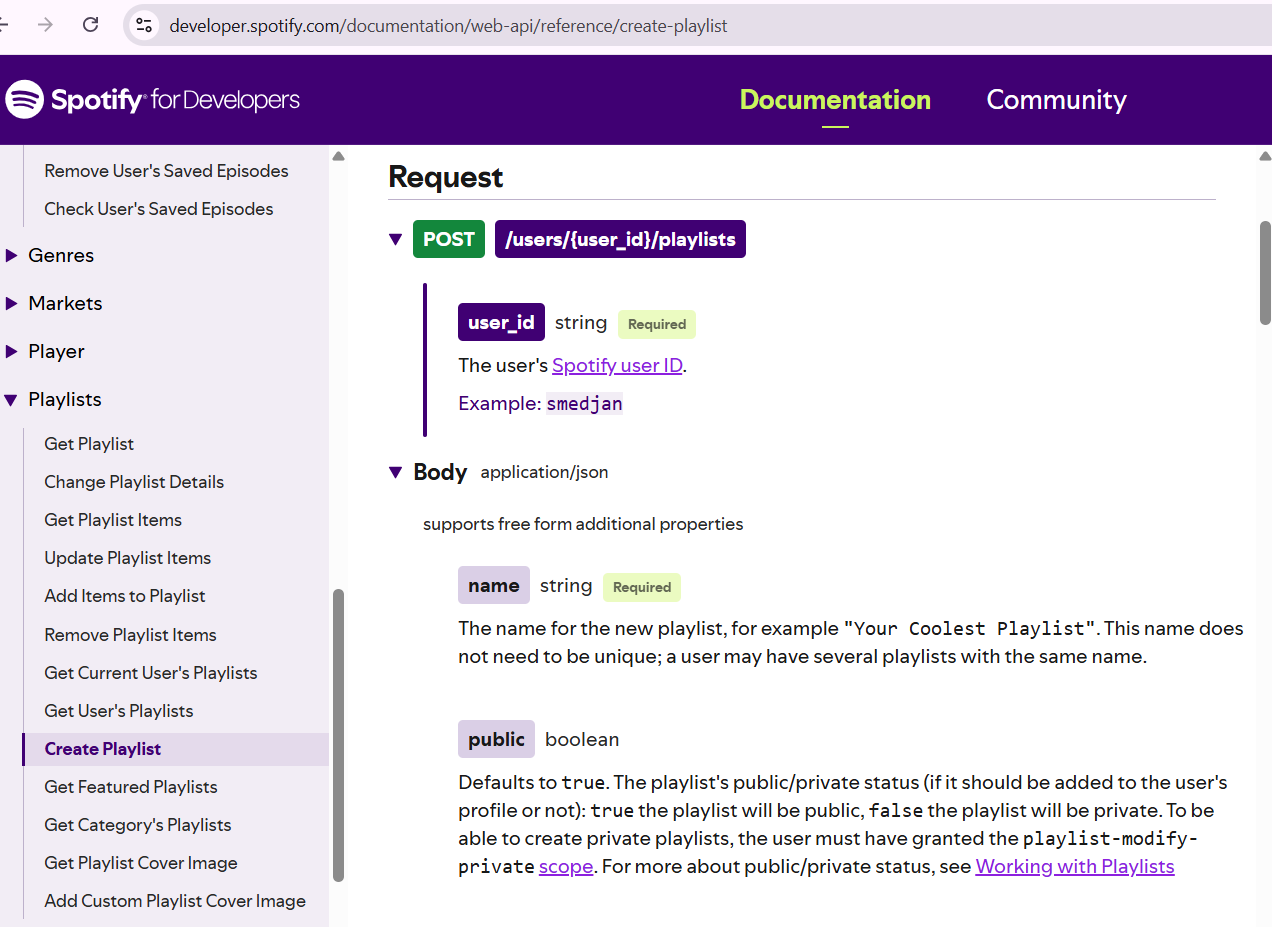


**POST /users/{user_id}/playlists**

PATH parameters:

*user_id*, string, Required, The user's Spotify user ID.

Body application/json
supports free form additional properties

*name*
string
Required
The name for the new playlist, for example "Your Coolest Playlist". This name does not need to be unique; a user may have several playlists with the same name.

*public*
boolean
Defaults to true. The playlist's public/private status (if it should be added to the user's profile or not): true the playlist will be public, false the playlist will be private. To be able to create private playlists, the user must have granted the playlist-modify-private scope. For more about public/private status, see Working with Playlists

*collaborative*
boolean
Defaults to false. If true the playlist will be collaborative. Note: to create a collaborative playlist you must also set public to false. To create collaborative playlists you must have granted playlist-modify-private and playlist-modify-public scopes.

*description*
string
value for playlist description as displayed in Spotify Clients and in the Web API.



b) ¿Qué solicitud de API utilizarías si quisieras saber en qué países está disponible Spotify?

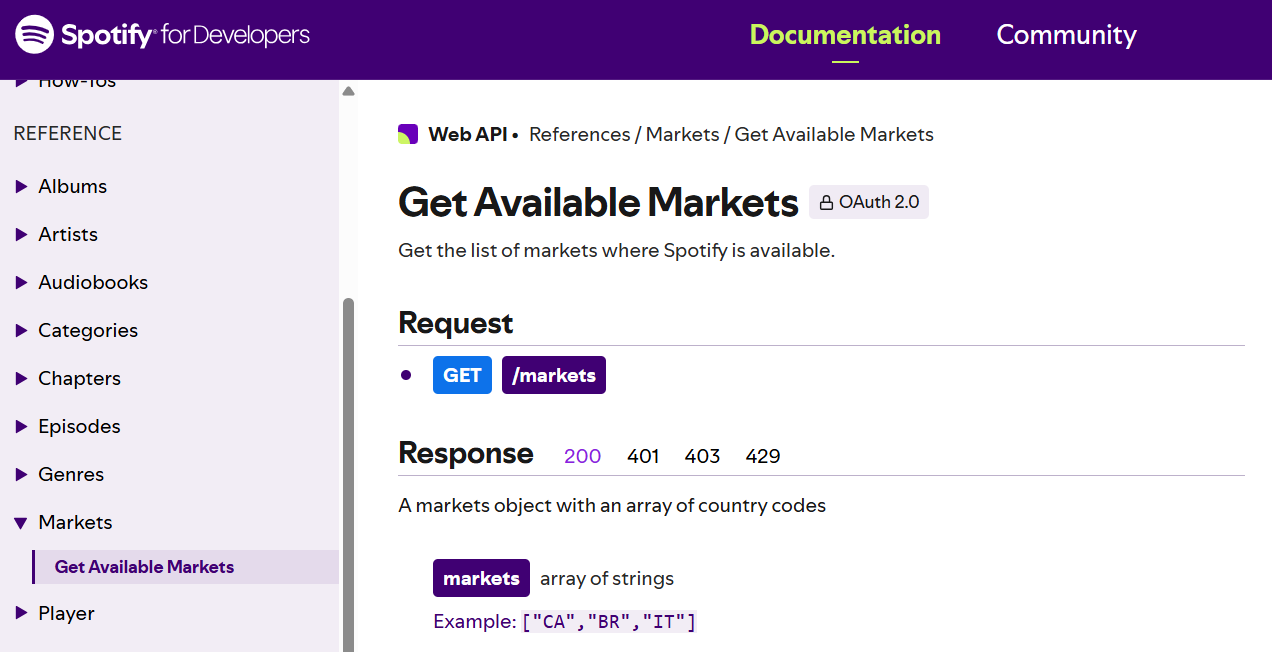

GET /markets




    

## Ejercicio 2

Utiliza un SDK para interactuar con la API de The Movie Database. Instala un paquete de Python para interactuar con The Movie Database y también un paquete de Python para interactuar con .env

Sugerencia: instala tmdbv3api y una librería para trabajar con .env

Documentación: https://github.com/AnthonyBloomer/tmdbv3api

Obtén datos sobre recomendaciones (de películas similares) y datos de películas populares 





In [1]:
%pip install tmdbv3api

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
%pip install python-dotenv

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
# go check your API key
# Note: themoviedatabase can work with either Bearer tokens (version 3 and version 4) or API Keys (version 3)

# https://www.themoviedb.org/settings/api

### Ejercicio 3

#### Para agilizar el proceso, puedes escribir el código directamente en una celda de este cuaderno de Jupyter

#### Utilizando requests, obtén las primeras 100 páginas con películas cuyo año de estreno (el primer año en que se estrenaron) sea 2026. Ordénalas por popularidad en orden descendente.

In [ ]:
import numpy as np
import pandas as pd
import pprint

from dotenv import dotenv_values

config = dotenv_values(".env")

import requests

headers = {
    "accept": "application/json",
    "Authorization": config['BEARER_token']
}

years = [2026]
#years = np.arange(2026, 2026)
id_movies = []
release_date = []
title = []
popularity = []
pages = []
for i in years:
    print("year:", i )
    for j in range(1,101): 
        response = requests.get(url=f'https://api.themoviedb.org/3/discover/movie?&page={j}&primary_release_year={i}&sort_by=popularity.desc', headers=headers)
        data_json = response.json()
        pprint.pp(data_json)
        
        first_results = data_json["results"]
       
        for k in first_results:
                     
            try:                
                release_date.append(k["release_date"])
                title.append(k["title"])
                id_movies.append(k["id"])
                popularity.append(k["popularity"])
                pages.append(j)
            except:
                release_date.append(np.nan)
                title.append(np.nan)
                id_movies.append(np.nan)
                popularity.append(np.nan)
                pages.append(np.nan)
                continue

df_movies_id = pd.DataFrame(id_movies, columns=["id"])
df_movies_id["date"] = release_date
df_movies_id["title"] = title
df_movies_id["popularity"] = popularity
df_movies_id["page"] = pages


year: 2026
{'page': 1,
 'results': [{'adult': False,
              'backdrop_path': '/4tjxYg2AbOzzG9G1YuiT2NzYhlH.jpg',
              'genre_ids': [878, 28, 12],
              'id': 969681,
              'title': 'Spider-Man: Brand New Day',
              'original_language': 'en',
              'original_title': 'Spider-Man: Brand New Day',
              'overview': 'Fighting crime full-time as Spider-Man in a world '
                          "that doesn't remember him—and the pressure of "
                          'seeing his old friends move on without him—sparks a '
                          'change in Peter Parker he may not have the power to '
                          'control. But that transformation might also be the '
                          'only thing that can stop a shocking new threat to '
                          'the city and those he loves - a powerful villain no '
                          'one can even see.',
              'popularity': 556.9527,
              '

In [7]:
df_movies_id

,id,date,title,popularity,page
0,969681,2026-07-29,Spider-Man: Brand New Day,556.9527,1
1,687163,2026-03-15,Project Hail Mary,200.1628,1
2,1058424,2026-07-15,Hope,541.9762,1
3,1368337,2026-07-15,The Odyssey,268.7043,1
4,1101412,2026-09-01,Fall 2: Deadpoint,286.5341,1
...,...,...,...,...,...
1995,1737989,2026-02-08,Bad Bunny's Super Bowl LX Halftime Show,3.3475,100
1996,1673393,2026-05-07,Krishnavataram Part 1: The Heart (Hridayam),3.0693,100
1997,1535392,2026-03-26,Malaikat Malam,2.6867,100
1998,1752463,2026-05-12,Deadlocked: Dad of the Dead,3.0125,100


## Ejercicio 4
### Búsqueda de aparcamientos
Para este caso práctico, imagina que vas a viajar a Madrid y estás buscando posibles aparcamientos donde dejar tu coche. Crea un DataFrame con todos los aparcamientos (de OpenStreetMap) de la ciudad de Madrid. Para ello, define una cuadrícula con dos coordenadas sobre Madrid.

Representa los resultados en un mapa.


    

In [6]:
def json_to_df(data):
    elements = data['elements']
    places = {'amenity': [], 'lat': [], 'lon': [], 'name': [], 'address': []}
    
    for i in elements:
        
        amenity = i.get('tags', None).get('amenity', None)
        latitude = i.get('lat', None)
        longitude = i.get('lon', None)
        name = i.get('tags', {}).get('name', "NO NAME")
        street = i.get('tags', {}).get('addr:street', "NO STREET")
        number = i.get('tags', {}).get('addr:housenumber', 9999)

        places['amenity'].append(amenity)
        places['lat'].append(latitude)
        places['lon'].append(longitude)
        places['name'].append(name)
        places['address'].append(street + ' ' + str(number))

            
    return pd.DataFrame(places)

In [10]:

import requests
import time

overpass_url = "https://overpass-api.de/api/interpreter"

headers = {
    "User-Agent": "CafeFinder/1.0 (contact: alberto@thebridge.tech)",
    "Accept": "application/json"
}

overpass_query = """
[out:json][timeout:25];
(
  node["amenity"="parking"](40.396013,-3.746999,40.480011,-3.625910);
  way["amenity"="parking"](40.396013,-3.746999,40.480011,-3.625910);
  relation["amenity"="parking"](40.396013,-3.746999,40.480011,-3.625910);
);
out center;
"""

data_parking = None
wait = 10

for attempt in range(5):
    try:
        response_parking = requests.post(
            overpass_url,
            data={"data": overpass_query},
            headers=headers,
            timeout=(10, 45)
        )

        print("Status:", response_parking.status_code)

        if response_parking.status_code in (429, 502, 503, 504):
            if attempt == 4:
                response_parking.raise_for_status()

            retry_after = response_parking.headers.get("Retry-After")
            delay = float(retry_after) if retry_after else wait

            print(f"Servidor ocupado. Reintentando en {delay:g} segundos...")
            time.sleep(delay)
            wait *= 2
            continue

        response_parking.raise_for_status()
        data_parking = response_parking.json()
        break

    except requests.exceptions.Timeout:
        if attempt == 4:
            raise

        print(f"Timeout. Esperando {wait} segundos...")
        time.sleep(wait)
        wait *= 2

if data_parking is not None:
    print("Número de aparcamientos:", len(data_parking["elements"]))

df_parking = json_to_df(data_parking)
df_parking

Status: 200
Número de aparcamientos: 2096


,amenity,lat,lon,name,address
0,parking,40.426712,-3.714370,Princesa 25,NO STREET 9999
1,parking,40.414469,-3.703549,Parking Benavente,NO STREET 9999
2,parking,40.406444,-3.708171,NO NAME,NO STREET 9999
3,parking,40.447447,-3.627856,NO NAME,NO STREET 9999
4,parking,40.476365,-3.643011,NO NAME,NO STREET 9999
...,...,...,...,...,...
2091,parking,NaN,NaN,NO NAME,NO STREET 9999
2092,parking,NaN,NaN,NO NAME,NO STREET 9999
2093,parking,NaN,NaN,P.A.R. Chaparral,Calle Choconta 9999
2094,parking,NaN,NaN,NO NAME,NO STREET 9999


In [5]:
import plotly.express as px


def plot_my_map(df):
    fig = px.scatter_map(df,
                            lat="lat",
                            lon="lon",
                            color = "amenity",
                      color_continuous_scale=px.colors.cyclical.IceFire, size_max=15, zoom=11)

    fig.show()

In [12]:
plot_my_map(df_parking)

## Ejercicio 5
### Mudanza
Imagina que quieres mudarte a El Berrueco, en la Comunidad de Madrid. Averigua si hay gasolineras y/o colegios en la zona. Al igual que en el caso anterior, define un rectángulo utilizando dos coordenadas. Busca la forma de realizar una única solicitud a la API.

A continuación, representa los colegios y las gasolineras en un mapa utilizando colores diferentes.

In [13]:
overpass_query = """
[out:json];
node["amenity"="fuel"]
  (40.851838, -3.627774, 40.941457, -3.481755);
out;
node["amenity"="school"]
  (40.851838, -3.627774, 40.941457, -3.481755);
out;
"""

In [14]:
import requests
import time

overpass_url = "https://overpass-api.de/api/interpreter"

headers = {
    "User-Agent": "CafeFinder/1.0 (contact: alberto@thebridge.tech)",
    "Accept": "application/json"
}

data_moving_house = None
wait = 10

for attempt in range(5):
    try:
        response = requests.post(
            overpass_url,
            data={"data": overpass_query},
            headers=headers,
            timeout=(10, 45)
        )

        print("Status:", response.status_code)

        if response.status_code in (429, 502, 503, 504):
            if attempt == 4:
                response.raise_for_status()

            retry_after = response.headers.get("Retry-After")
            delay = float(retry_after) if retry_after else wait

            print(f"Servidor ocupado. Reintentando en {delay:g} segundos...")
            time.sleep(delay)
            wait *= 2
            continue

        response.raise_for_status()
        data_moving_house = response.json()
        break

    except requests.exceptions.Timeout:
        if attempt == 4:
            raise

        print(f"Timeout. Esperando {wait} segundos...")
        time.sleep(wait)
        wait *= 2

if data_moving_house is not None:
    df_moving_house = json_to_df(data_moving_house)
    display(df_moving_house)

Status: 200


,amenity,lat,lon,name,address
0,fuel,40.905376,-3.607588,Repsol,NO STREET 9999
1,fuel,40.906677,-3.610172,Shell,CTRA. N-I KM 64.650 9999
2,fuel,40.856872,-3.612894,Shell,Avenida de La Cabrera 12
3,fuel,40.875833,-3.602389,Shell,Avenida de La Cabrera 9999
4,school,40.864566,-3.614058,Equipo de Orientación Educativa y Psicopedagóg...,Calle de Carlos Ruiz 8
5,school,40.872395,-3.608802,C.A.P. De La Cabrera,Calle los Colegios 28
6,school,40.863864,-3.615523,Equipo de Orientación Educativa y Psicopedagóg...,Calle de Carlos Ruiz 2
7,school,40.872395,-3.608802,C.A.P. De La Cabrera,Calle los Colegios 28


In [2]:

import requests
import time

overpass_url = "https://overpass-api.de/api/interpreter"

headers = {
    "User-Agent": "CafeFinder/1.0 (contact: alberto@thebridge.tech)",
    "Accept": "application/json"
}

overpass_query = """
[out:json][timeout:25];
(
  node["amenity"~"^(fuel|school)$"](40.851838,-3.627774,40.941457,-3.481755);
  way["amenity"~"^(fuel|school)$"](40.851838,-3.627774,40.941457,-3.481755);
  relation["amenity"~"^(fuel|school)$"](40.851838,-3.627774,40.941457,-3.481755);
);
out center;
"""

data = None
wait = 10

for attempt in range(5):
    try:
        response = requests.post(
            overpass_url,
            data={"data": overpass_query},
            headers=headers,
            timeout=(10, 45)
        )

        print("Status:", response.status_code)

        if response.status_code in (429, 502, 503, 504):
            if attempt == 4:
                response.raise_for_status()

            retry_after = response.headers.get("Retry-After")
            delay = float(retry_after) if retry_after else wait

            print(f"Servidor ocupado. Reintentando en {delay:g} segundos...")
            time.sleep(delay)
            wait *= 2
            continue

        response.raise_for_status()
        data = response.json()
        break

    except requests.exceptions.Timeout:
        if attempt == 4:
            raise

        print(f"Timeout. Esperando {wait} segundos...")
        time.sleep(wait)
        wait *= 2

if data is not None:
    print("Elementos encontrados:", len(data["elements"]))


Status: 200
Elementos encontrados: 14


In [9]:
if data is not None:
    df_moving_house = json_to_df(data)
    display(df_moving_house)

,amenity,lat,lon,name,address
0,school,40.864566,-3.614058,Equipo de Orientación Educativa y Psicopedagóg...,Calle de Carlos Ruiz 8
1,school,40.872395,-3.608802,C.A.P. De La Cabrera,Calle los Colegios 28
2,school,40.863864,-3.615523,Equipo de Orientación Educativa y Psicopedagóg...,Calle de Carlos Ruiz 2
3,fuel,40.905376,-3.607588,Repsol,NO STREET 9999
4,fuel,40.906677,-3.610172,Shell,CTRA. N-I KM 64.650 9999
5,fuel,40.856872,-3.612894,Shell,Avenida de La Cabrera 12
6,fuel,40.875833,-3.602389,Shell,Avenida de La Cabrera 9999
7,school,40.872395,-3.608802,C.A.P. De La Cabrera,Calle los Colegios 28
8,school,NaN,NaN,Colegio de Educación Infantil y Primaria Pico ...,Calle los Colegios 28
9,school,NaN,NaN,Instituto de Educación Secundaria De la Cabrera,Calle de las Azucenas 12


In [10]:
plot_my_map(df_moving_house)

## Ejercicio 6

Imagina que trabajas para tu ayuntamiento y que, debido a una emergencia, necesitas identificar:
1. Todos los espacios abiertos de uso público (zonas de barbacoa, fuentes y parques infantiles) para poder cerrarlos.
2. Todos los hospitales y clínicas de la zona.

Como no sabes exactamente dónde se encuentran estos lugares, utilizas la API de OpenStreetMap. Esta muestra toda la información en un único mapa.

In [11]:

import requests
import time

overpass_url = "https://overpass-api.de/api/interpreter"

headers = {
    "User-Agent": "CafeFinder/1.0 (contact: alberto@thebridge.tech)",
    "Accept": "application/json"
}

overpass_query = """
[out:json][timeout:25];
(
  node["amenity"="bbq"](40.410505,-3.715351,40.448860,-3.677615);
  node["amenity"="drinking_water"](40.410505,-3.715351,40.448860,-3.677615);
  node["amenity"="hospital"](40.410505,-3.715351,40.448860,-3.677615);
  node["amenity"="clinic"](40.410505,-3.715351,40.448860,-3.677615);
  node["amenity"="kindergarten"](40.410505,-3.715351,40.448860,-3.677615);
);
out;
"""

data = None
wait = 10

for attempt in range(5):
    try:
        response = requests.post(
            overpass_url,
            data={"data": overpass_query},
            headers=headers,
            timeout=(10, 45)
        )

        print("Status:", response.status_code)

        if response.status_code in (429, 502, 503, 504):
            if attempt == 4:
                response.raise_for_status()

            retry_after = response.headers.get("Retry-After")
            delay = float(retry_after) if retry_after else wait

            print(f"Servidor ocupado. Reintentando en {delay:g} segundos...")
            time.sleep(delay)
            wait *= 2
            continue

        response.raise_for_status()
        data = response.json()
        break

    except requests.exceptions.Timeout:
        if attempt == 4:
            raise

        print(f"Timeout. Esperando {wait} segundos...")
        time.sleep(wait)
        wait *= 2

if data is not None:
    df = json_to_df(data)
    display(df)


Status: 200


,amenity,lat,lon,name,address
0,drinking_water,40.413707,-3.695723,NO NAME,NO STREET 9999
1,kindergarten,40.427418,-3.708993,Centro Privado de Educación Infantil Comendado...,Plaza de las Comendadoras 10
2,kindergarten,40.430843,-3.706032,Escuela Infantil Privada Nuestra Señora de los...,Calle de San Bernardo 99
3,kindergarten,40.446606,-3.680267,Hansel y Grethel,Calle de Rodríguez Marín 46
4,kindergarten,40.434176,-3.714909,Escuela Infantil Privada Agarimo,Calle de Fernando el Católico 61
...,...,...,...,...,...
281,drinking_water,40.411677,-3.711458,NO NAME,NO STREET 9999
282,drinking_water,40.437448,-3.686109,NO NAME,NO STREET 9999
283,drinking_water,40.428902,-3.709364,NO NAME,NO STREET 9999
284,drinking_water,40.413014,-3.708264,NO NAME,NO STREET 9999


In [12]:
plot_my_map(df)

## Ejercicio 7

### API de YouTube

Añade google-api-python-client desde PyPi.


In [14]:
%pip install google-api-python-client

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/16.8 MB ? eta -:--:--
   -- ------------------------------------- 1.0/16.8 MB 5.3 MB/s eta 0:00:03
   ----- ---------------------------------- 2.4/16.8 MB 5.8 MB/s eta 0:00:03
   -------- ------------------------------- 3.7/16.8 MB 5.9 MB/s eta 0:00:03
   ----------- ---------------------------- 4.7/16.8 MB 5.8 MB/s eta 0:00:03
   -------------- ------------------------- 6.0/16.8 MB 5.8 MB/s eta 0:00:02
   ---------------- ----------------------- 7.1/16.8 MB 5.9 MB/s eta 0:00:02
   ------------------- -------------------- 8.4/16.8 MB 5.7 MB/s eta 0:00:02
   ----------------------- ---------------- 9.7/16.8 MB 5.8 MB/s eta 0:00:02
   -------------------------- ------------- 11.0/16.8 MB 5.8 MB/s eta 0:00:02
   ----------------------------- ---------- 12.3/16.8 MB 5.8 MB/s eta 0:00:01
   -------------------------------- ------- 13.6/16.8 MB 5.8 MB/s eta 0:00:01
  


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
from googleapiclient.discovery import build

El ID del vídeo se encuentra en la URL de la página del vídeo, justo después del parámetro v=.

En este caso, la URL del vídeo es: https://www.youtube.com/watch?v=fn3KWM1kuAw. Por lo tanto, el ID del vídeo es fn3KWM1kuAw 

In [ ]:
#   https://cloud.google.com/console to create the project and activate the API key of youtube v3
#   https://console.cloud.google.com/projectselector2/apis/credentials --> create a project

# Create credentials --> get the API key

# Now link the API key to the services it can use!
# APIs and services library

# https://developers.google.com/youtube/v3/quickstart/python --> API key
# Ensure that you have enabled the YouTube Data API for your project.

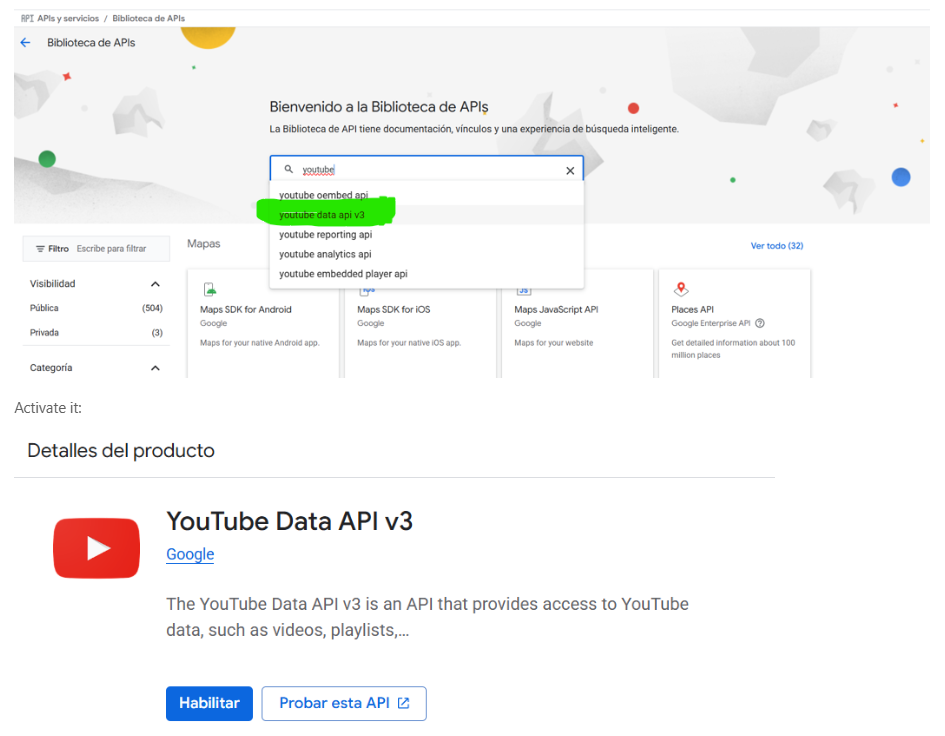

In [2]:

#api_key_y = "your api key"

from dotenv import dotenv_values

config = dotenv_values(".env")
api_key_y = config['YOUTUBE_API_KEY']

youtube = build("youtube", "v3", developerKey=api_key_y)


request = youtube.channels().list(
    part="statistics",
    id = "fn3KWM1kuAw"
)

response = request.execute()

In [3]:
response

{'kind': 'youtube#channelListResponse',
 'etag': 'RuuXzTIr0OoDqI4S0RU6n4FqKEM',
 'pageInfo': {'totalResults': 0, 'resultsPerPage': 5}}

### ¡Puedes hacer búsquedas como si estuvieras en la barra de búsqueda de Youtube!

In [4]:
search_response = youtube.search().list(
    q="Dancing robots",
    part="snippet",
    order="viewCount",
    type="video",
    maxResults=50
).execute()

In [5]:
search_response["items"][0]["snippet"]

{'publishedAt': '2020-02-10T13:30:00Z',
 'channelId': 'UC8NFs-VWUsyuq4zaYVVMgCQ',
 'title': 'The Dance Freeze Song | Freeze Dance | Scratch Garden',
 'description': 'A BRAND NEW Freeze Dance is here! https://youtu.be/L1o6SabKfC4 The Dance Freeze Song by Scratch Garden is the ...',
 'thumbnails': {'default': {'url': 'https://i.ytimg.com/vi/A1vdKfXlB_g/default.jpg',
   'width': 120,
   'height': 90},
  'medium': {'url': 'https://i.ytimg.com/vi/A1vdKfXlB_g/mqdefault.jpg',
   'width': 320,
   'height': 180},
  'high': {'url': 'https://i.ytimg.com/vi/A1vdKfXlB_g/hqdefault.jpg',
   'width': 480,
   'height': 360},
  'standard': {'url': 'https://i.ytimg.com/vi/A1vdKfXlB_g/sddefault.jpg',
   'width': 640,
   'height': 480},
  'maxres': {'url': 'https://i.ytimg.com/vi/A1vdKfXlB_g/maxresdefault.jpg',
   'width': 1280,
   'height': 720}},
 'channelTitle': 'Scratch Garden',
 'liveBroadcastContent': 'none',
 'publishTime': '2020-02-10T13:30:00Z'}

In [6]:
import pandas as pd

dict_videos = {"id":[], "channelTitle":[], "publish":[], "description":[], "title_video":[]} 

for i in search_response["items"]: # 
    dict_videos["id"].append(i["id"]["videoId"]) 
    dict_videos["channelTitle"].append(i["snippet"]["channelTitle"])
    dict_videos["publish"].append(i["snippet"]["publishTime"])
    dict_videos["description"].append(i["snippet"]["description"])
    dict_videos["title_video"].append(i["snippet"]["title"])

df_video_y = pd.DataFrame(dict_videos)
df_video_y

,id,channelTitle,publish,description,title_video
0,A1vdKfXlB_g,Scratch Garden,2020-02-10T13:30:00Z,A BRAND NEW Freeze Dance is here! https://yout...,The Dance Freeze Song | Freeze Dance | Scratch...
1,_QNbbE5hb5U,D Billions,2023-02-09T08:52:01Z,"https://band.link/DBillions Lyrics: Robo, robo...","Robot Cha-Cha, Robot Chicky, Robot Boom-Boom &..."
2,XwfG9FdhAc0,charles agha,2020-11-04T01:18:54Z,Dance video created to the awesome theme song ...,AMONG US Dance Video - Moondai EDM Remix (DTB)
3,cn-NsWRtaSY,America's Got Talent,2013-06-19T01:17:24Z,You've never seen dancing done like this! From...,Kenichi Ebina Performs an Epic Matrix- Style M...
4,c6nf0ursWZs,stance,2022-08-31T14:00:30Z,,Robots are getting more lifelike 🤯
5,DMqQtylat3U,stance,2023-07-12T16:03:31Z,,Chibi the real life robot 🤖
6,iH58C67wEQw,Teehee Town,2024-01-12T00:00:20Z,Skeleton Robot Finger Family is here to make u...,Skeleton Robot Finger Family - Midnight Lab St...
7,mKgl1CiA9Qk,Danny Go!,2025-08-25T12:01:24Z,Are you ready to use your superpowers? ⚡ ‍♂️ ...,Ka-Pow! 2: Attack of the Gravity Goldfish! 💥 S...
8,prvA-qUptp0,ngsmoov,2012-10-19T17:30:03Z,It was inevitable that Randall Ng would make t...,PSY - GANGNAM STYLE (강남스타일) ft. TRANSFORMERS
9,u-A3nCIvUGs,Danny Go!,2023-06-05T12:00:45Z,Are you ready to BOUNCE?? Dance along with Dan...,&quot;Bouncing Time!&quot; Dance Song 🐰 | Brai...


### Escribe un programa que le pida a Youtube "¿cómo hacer pan?", 50 resultados, obtén los snippets y guarda los siguientes datos:

* id_video
* channelTitle
* publish_time
* description
* title_video
* duration
* definition
* closed_caption
* license_content
* madeforkids
* view_count
* like_count
* favorite_count
* comment_count
* license

In [7]:
# Your code:

search_response = youtube.search().list(
  q="¿cómo hacer pan?",
  part="snippet",
  order="viewCount",
  type="video",
  maxResults=50
).execute()

id_video = []
channelTitle = []
publish_time = []
description = []
title_video = []

for search_result in search_response.get("items", []):
    id_video.append(search_result["id"]["videoId"])
    channelTitle.append(search_result["snippet"]["channelTitle"])
    publish_time.append(search_result["snippet"]["publishTime"])
    description.append(search_result["snippet"]["description"])
    title_video.append(search_result["snippet"]["title"])


duration = []
definition = []
closed_caption = []
license_content = []
madeforkids = []
view_count = []
like_count = []
favorite_count = []
comment_count = []
license = []

for id_video_search in id_video:
    video_info_response = youtube.videos().list(
      part = ["contentDetails", "statistics","status"],
      id = id_video_search
    ).execute()

    duration .append(video_info_response["items"][0]['contentDetails']["duration"])
    definition.append(video_info_response["items"][0]['contentDetails']["definition"])
    closed_caption.append(video_info_response["items"][0]['contentDetails']["caption"])
    license_content.append(video_info_response["items"][0]['contentDetails']["licensedContent"])
    madeforkids.append(video_info_response["items"][0]['status']["madeForKids"])
    license.append(video_info_response["items"][0]['status']["license"])
    view_count.append(video_info_response["items"][0]['statistics']["viewCount"])
    favorite_count.append(video_info_response["items"][0]['statistics']["favoriteCount"])
    comment_count.append(video_info_response["items"][0]['statistics'].get("commentCount", None))
    

df_youtube = pd.DataFrame({"id_video": id_video,
                           "Channel": channelTitle,
                           "title" : title_video,
                           "description": description,
                           "publish_time": publish_time,
                           "duration":duration,
                           "definiton": definition,
                           "closed_caption":closed_caption,
                           "license_content": license_content,
                           "madeforkids":madeforkids,
                           "license": license,
                           "view_count": view_count,
                           "favorite_count" : favorite_count,
                           "comment_count": comment_count
                           })
df_youtube.head()

,id_video,Channel,title,description,publish_time,duration,definiton,closed_caption,license_content,madeforkids,license,view_count,favorite_count,comment_count
0,ebTI4nm2cg8,By Tahiana Fandiño,"PAN SIN HARINA, en la descripción te dejo los ...",PAN DE CREMA DE MANI ( pan sin harina) Ingredi...,2024-08-31T03:20:04Z,PT1M1S,hd,false,True,True,youtube,50740679,0,NaN
1,Bc7KNDrheaQ,Anna recetasfaciles,Pan casero fácil y rápido (con harina común),Compra mi libro de recetas COCINA PARA TRIUNFA...,2017-06-21T20:39:34Z,PT5M3S,hd,true,True,False,youtube,10651845,0,6984
2,P7LUKvvPGB8,Ailu Tokman,SOBRÓ PAN DEL ASADO DEL DOMINGO? HAZ ESTA RECE...,Sobró pan del asado del domingo? HACETE TREMEN...,2022-10-23T23:00:17Z,PT57S,hd,false,True,False,youtube,10029663,0,1919
3,8efWPwnDJLY,Anna recetasfaciles,Cómo hacer PAN SIN HORNO con harina común,Compra mi libro de recetas COCINA PARA TRIUNFA...,2020-07-15T17:27:05Z,PT8M34S,hd,false,True,False,youtube,9804201,0,4610
4,KcKe8z6ZjX0,Paulina Cocina,CÓMO HACER BUDÍN DE PAN: Receta fácil en 4 pasos!,CÓMO HACER BUDÍN DE PAN FÁCIL Y PERFECTO En es...,2017-07-12T19:37:01Z,PT10M9S,hd,true,True,False,youtube,8116271,0,4875


In [8]:
df_youtube

,id_video,Channel,title,description,publish_time,duration,definiton,closed_caption,license_content,madeforkids,license,view_count,favorite_count,comment_count
0,ebTI4nm2cg8,By Tahiana Fandiño,"PAN SIN HARINA, en la descripción te dejo los ...",PAN DE CREMA DE MANI ( pan sin harina) Ingredi...,2024-08-31T03:20:04Z,PT1M1S,hd,false,True,True,youtube,50740679,0,NaN
1,Bc7KNDrheaQ,Anna recetasfaciles,Pan casero fácil y rápido (con harina común),Compra mi libro de recetas COCINA PARA TRIUNFA...,2017-06-21T20:39:34Z,PT5M3S,hd,true,True,False,youtube,10651845,0,6984
2,P7LUKvvPGB8,Ailu Tokman,SOBRÓ PAN DEL ASADO DEL DOMINGO? HAZ ESTA RECE...,Sobró pan del asado del domingo? HACETE TREMEN...,2022-10-23T23:00:17Z,PT57S,hd,false,True,False,youtube,10029663,0,1919
3,8efWPwnDJLY,Anna recetasfaciles,Cómo hacer PAN SIN HORNO con harina común,Compra mi libro de recetas COCINA PARA TRIUNFA...,2020-07-15T17:27:05Z,PT8M34S,hd,false,True,False,youtube,9804201,0,4610
4,KcKe8z6ZjX0,Paulina Cocina,CÓMO HACER BUDÍN DE PAN: Receta fácil en 4 pasos!,CÓMO HACER BUDÍN DE PAN FÁCIL Y PERFECTO En es...,2017-07-12T19:37:01Z,PT10M9S,hd,true,True,False,youtube,8116271,0,4875
5,Qz551QovGJU,Recetas Tradicionales de Cocina,Cómo hacer pan casero de forma fácil,No te pierdas esta receta fácil para elaborar ...,2015-02-06T12:38:20Z,PT4M25S,hd,false,True,False,youtube,8041844,0,2826
6,xmWPoBn7ZD4,Oye Kenedy,TE APUESTO QUE NO SABÍAS ESTO 😨‼️ la forma más...,,2025-07-07T04:39:00Z,PT1M13S,hd,false,True,False,youtube,12600059,0,2162
7,I_8RlzV7qsA,Gluten Morgen Español,"Cómo hacer masa madre, la forma fácil y defini...",La guía definitiva para hacer masa madre fácil...,2023-08-12T16:00:11Z,PT1M,hd,false,True,False,youtube,8757171,0,3174
8,6snDDoeV3W0,Dulce Hogar Recetas,DELICIOSOS BOLILLOS CASEROS con TIPS para que ...,QuédateEnCasa #conmigo Deliciosos BOLILLOS CAS...,2020-04-24T15:15:00Z,PT13M37S,hd,false,True,False,youtube,7606301,0,5373
9,gm5wSHC6KpE,Jauja Cocina Mexicana,Cómo Hacer el Pan Francés Perfecto,Pan Francés. Pan Francés de Jauja Cocina Mexic...,2018-06-08T13:45:01Z,PT4M53S,hd,false,True,False,youtube,7593414,0,3673
